In [1]:
# ============================================
# CELL 1: Load Libraries and Kaggle Dataset
# ============================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Load Kaggle dataset (semicolon separated)
df = pd.read_csv(r"C:\Users\CYBORG 15\Downloads\Container_Terminal_EventLog_Dataset_Kaggle\container_terminal_dwelling_time.csv", sep=";")

# Basic info
print("=" * 50)
print("KAGGLE DATASET LOADED SUCCESSFULLY")
print("=" * 50)
print(f"Total rows: {len(df):,}")
print(f"Columns: {list(df.columns)}")
print(f"Unique containers: {df['Case_ID'].str.split('-').str[0].nunique():,}")
print("=" * 50)
df.head(10)

KAGGLE DATASET LOADED SUCCESSFULLY
Total rows: 952,069
Columns: ['Case_ID', 'Activity', 'Timestamp', 'Posision']
Unique containers: 95,567


,Case_ID,Activity,Timestamp,Posision
0,AAAU9001220-2021-06-28,BAPLIE,6/27/21 11.09,EDI BAPLIE
1,AAAU9001220-2021-06-28,VESSEL_ATB,6/28/21 20.00,Dock spv
2,AAAU9001220-2021-06-28,DISCHARGE,6/28/21 22.22,"tally, CC OP"
3,AAAU9001220-2021-06-28,STACK,6/28/21 22.40,RTG OP
4,AAAU9001220-2021-06-28,HAS_QUARANTINE_FLAG,07.02.2021 09:06,CT Staff
5,AAAU9001220-2021-06-28,FIRST_STACK_QUARANTINE_BLK,07.03.2021 01:43,RS OP
6,AAAU9001220-2021-06-28,CUSTOMS_DEL,07.05.2021 00:00,Custom Staff
7,AAAU9001220-2021-06-28,QUARANTINE_RELEASE,07.05.2021 14:15,CT Staff
8,AAAU9001220-2021-06-28,JOB_DEL,07.05.2021 17:13,CT Staff
9,AAAU9001220-2021-06-28,TRUCK_IN,07.06.2021 06:33,CT Staff


In [2]:
# ============================================
# CELL 2: Calculate Dwell Time for Each Container
# ============================================

# Parse timestamps (mixed formats in dataset)
# Times use a dot as separator ("6/27/21 11.09", "7/21/21 9.53") - convert the trailing
# H.MM / HH.MM to H:MM so they parse. Anchored at the end of the string so dates like
# "07.02.2021 09:06" are left untouched.
df['Timestamp'] = df['Timestamp'].str.strip()
df['Timestamp'] = df['Timestamp'].str.replace(r'(\d{1,2})\.(\d{2})\s*$', r'\1:\2', regex=True)
df['Timestamp'] = pd.to_datetime(df['Timestamp'], dayfirst=False, errors='coerce')
print(f"Unparsed timestamps: {df['Timestamp'].isna().sum():,}")

# Get DISCHARGE time (container arrives at yard)
discharge = df[df['Activity'] == 'DISCHARGE'].groupby('Case_ID')['Timestamp'].first().reset_index()
discharge.columns = ['Case_ID', 'Discharge_Time']

# Get TRUCK_OUT time (container leaves yard)
truck_out = df[df['Activity'] == 'TRUCK_OUT'].groupby('Case_ID')['Timestamp'].first().reset_index()
truck_out.columns = ['Case_ID', 'TruckOut_Time']

# Merge and calculate dwell time
dwell = pd.merge(discharge, truck_out, on='Case_ID', how='inner')
dwell['Dwell_Hours'] = (dwell['TruckOut_Time'] - dwell['Discharge_Time']).dt.total_seconds() / 3600
dwell['Dwell_Days'] = dwell['Dwell_Hours'] / 24

# Remove invalid records (negative or zero dwell, or extreme outliers > 90 days)
dwell = dwell[(dwell['Dwell_Hours'] > 0) & (dwell['Dwell_Days'] <= 90)]

# Extract time features for ML models
dwell['Month'] = dwell['Discharge_Time'].dt.month
dwell['DayOfWeek'] = dwell['Discharge_Time'].dt.dayofweek
dwell['Hour'] = dwell['Discharge_Time'].dt.hour
dwell['Date'] = dwell['Discharge_Time'].dt.date

# Modelling window for the time-series models.
# The dataset only contains containers whose full journey (DISCHARGE -> TRUCK_OUT) was
# recorded. Before July only a handful of long-staying containers appear (left edge), and
# containers discharged in late September are only included if they had already left
# (right edge), so their dwell looks artificially short. Both edges are excluded.
WINDOW_START = pd.Timestamp('2021-07-01')
WINDOW_END = pd.Timestamp('2021-09-20')

# Scope of the proposal: ONE yard block (Yard Block 01). The data covers the whole terminal
# and does not record blocks, so the block is assumed to receive a fixed share of the
# terminal's containers (a terminal of this size runs several blocks).
BLOCK_SHARE = 0.25

print("=" * 50)
print("DWELL TIME CALCULATED SUCCESSFULLY")
print("=" * 50)
print(f"Containers with both DISCHARGE & TRUCK_OUT: {len(dwell):,}")
print(f"Average dwell time: {dwell['Dwell_Days'].mean():.1f} days ({dwell['Dwell_Hours'].mean():.1f} hours)")
print(f"Median dwell time: {dwell['Dwell_Days'].median():.1f} days")
print(f"Min: {dwell['Dwell_Days'].min():.2f} days | Max: {dwell['Dwell_Days'].max():.1f} days")
print(f"Modelling window: {WINDOW_START.date()} to {WINDOW_END.date()}")
print("=" * 50)
dwell.head(10)

Unparsed timestamps: 0
DWELL TIME CALCULATED SUCCESSFULLY
Containers with both DISCHARGE & TRUCK_OUT: 95,643
Average dwell time: 3.3 days (79.7 hours)
Median dwell time: 2.2 days
Min: 0.01 days | Max: 85.2 days
Modelling window: 2021-07-01 to 2021-09-20


,Case_ID,Discharge_Time,TruckOut_Time,Dwell_Hours,Dwell_Days,Month,DayOfWeek,Hour,Date
0,AAAU9001220-2021-06-28,2021-06-28 22:22:00,2021-07-06 06:51:00,176.483333,7.353472,6,0,22,2021-06-28
1,AAMU2609009-2021-09-26,2021-09-26 14:12:00,2021-09-29 21:17:00,79.083333,3.295139,9,6,14,2021-09-26
2,AAMU2609164-2021-09-07,2021-09-07 19:40:00,2021-09-10 08:48:00,61.133333,2.547222,9,1,19,2021-09-07
3,AAMU4000372-2021-09-07,2021-09-07 16:25:00,2021-09-08 20:15:00,27.833333,1.159722,9,1,16,2021-09-07
4,AAMU4000705-2021-09-07,2021-09-07 07:25:00,2021-09-07 23:54:00,16.483333,0.686806,9,1,7,2021-09-07
5,AAMU4001070-2021-08-28,2021-08-29 01:02:00,2021-08-31 07:32:00,54.500000,2.270833,8,6,1,2021-08-29
6,AAMU4001954-2021-08-02,2021-08-03 00:21:00,2021-08-06 01:50:00,73.483333,3.061806,8,1,0,2021-08-03
7,AAMU4002225-2021-09-21,2021-09-21 23:44:00,2021-09-22 14:53:00,15.150000,0.631250,9,1,23,2021-09-21
8,AAMU4002436-2021-09-07,2021-09-07 05:55:00,2021-09-09 17:50:00,59.916667,2.496528,9,1,5,2021-09-07
9,AAMU4002462-2021-09-21,2021-09-22 00:37:00,2021-09-22 15:17:00,14.666667,0.611111,9,2,0,2021-09-22


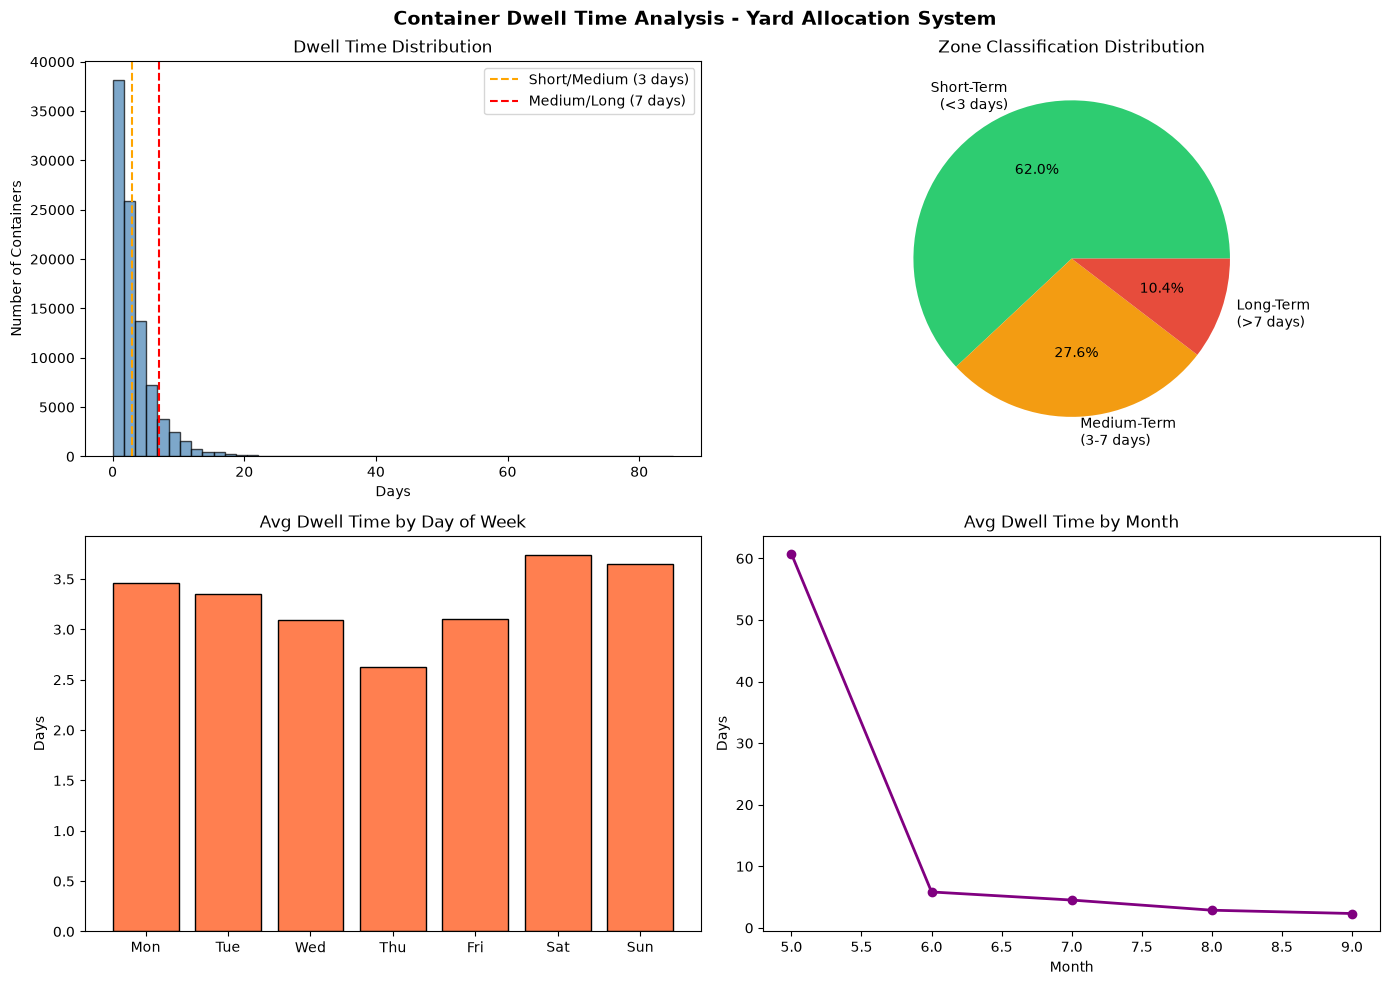


Zone Distribution:
  Short-Term (<3 days):  59,271 containers (62.0%)
  Medium-Term (3-7 days): 26,425 containers (27.6%)
  Long-Term (>7 days):   9,947 containers (10.4%)


In [3]:
# ============================================
# CELL 3: Data Exploration & Visualization
# ============================================
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('Container Dwell Time Analysis - Yard Allocation System', fontsize=14, fontweight='bold')

# 1. Dwell time distribution
axes[0,0].hist(dwell['Dwell_Days'], bins=50, color='steelblue', edgecolor='black', alpha=0.7)
axes[0,0].set_title('Dwell Time Distribution')
axes[0,0].set_xlabel('Days')
axes[0,0].set_ylabel('Number of Containers')
axes[0,0].axvline(x=3, color='orange', linestyle='--', label='Short/Medium (3 days)')
axes[0,0].axvline(x=7, color='red', linestyle='--', label='Medium/Long (7 days)')
axes[0,0].legend()

# 2. Zone classification pie chart
zones = pd.cut(dwell['Dwell_Days'], bins=[0, 3, 7, 90], labels=['Short-Term\n(<3 days)', 'Medium-Term\n(3-7 days)', 'Long-Term\n(>7 days)'])
zone_counts = zones.value_counts(sort=False)
axes[0,1].pie(zone_counts, labels=zone_counts.index, autopct='%1.1f%%', colors=['#2ecc71','#f39c12','#e74c3c'])
axes[0,1].set_title('Zone Classification Distribution')

# 3. Average dwell time by day of week
daily_avg = dwell.groupby('DayOfWeek')['Dwell_Days'].mean()
days = ['Mon','Tue','Wed','Thu','Fri','Sat','Sun']
axes[1,0].bar(days, daily_avg.values, color='coral', edgecolor='black')
axes[1,0].set_title('Avg Dwell Time by Day of Week')
axes[1,0].set_ylabel('Days')

# 4. Monthly trend
monthly_avg = dwell.groupby('Month')['Dwell_Days'].mean()
axes[1,1].plot(monthly_avg.index, monthly_avg.values, 'o-', color='purple', linewidth=2)
axes[1,1].set_title('Avg Dwell Time by Month')
axes[1,1].set_xlabel('Month')
axes[1,1].set_ylabel('Days')

plt.tight_layout()
plt.savefig('dwell_time_analysis.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"\nZone Distribution:")
print(f"  Short-Term (<3 days):  {zone_counts.iloc[0]:,} containers ({zone_counts.iloc[0]/len(dwell)*100:.1f}%)")
print(f"  Medium-Term (3-7 days): {zone_counts.iloc[1]:,} containers ({zone_counts.iloc[1]/len(dwell)*100:.1f}%)")
print(f"  Long-Term (>7 days):   {zone_counts.iloc[2]:,} containers ({zone_counts.iloc[2]/len(dwell)*100:.1f}%)")

Training set: 65 days
Testing set: 17 days



ARIMA MODEL TRAINED SUCCESSFULLY (Baseline)
Hold-out test  -> RMSE: 0.4284 | MAE: 0.3561 | MAPE: 14.37%
Rolling 7-day  -> RMSE: 0.4282 | MAE: 0.3680 | MAPE: 16.75%


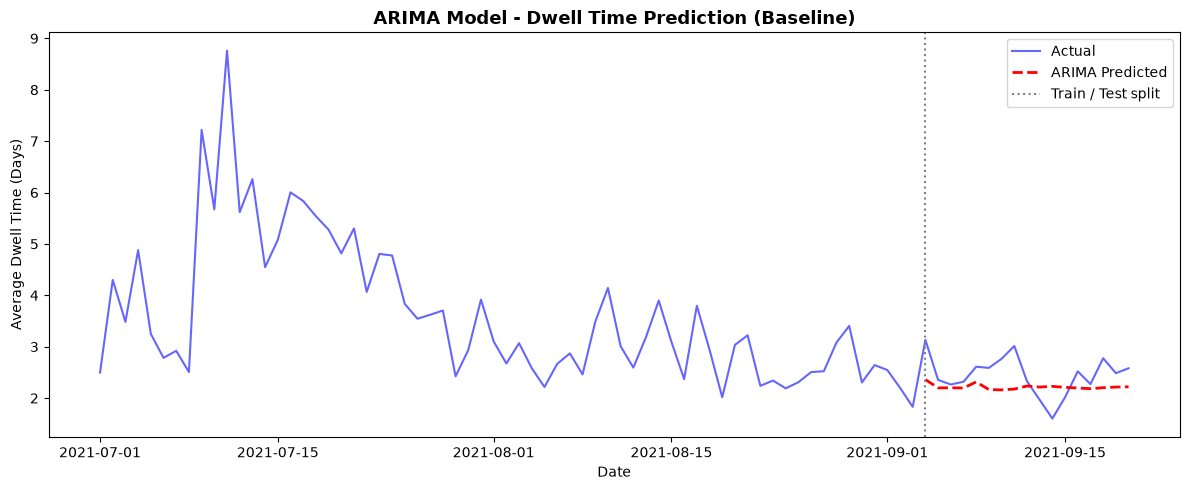

In [4]:
# ============================================
# CELL 4: Train ARIMA Model (Baseline)
# ============================================
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_absolute_error, mean_squared_error
import warnings
warnings.filterwarnings('ignore')

# Prepare a continuous daily average dwell time series inside the modelling window.
# The SAME series and the SAME split are used for ARIMA and Prophet.
dwell_dates = pd.to_datetime(dwell['Date'])
in_window = dwell[(dwell_dates >= WINDOW_START) & (dwell_dates <= WINDOW_END)]
daily_series = in_window.groupby(pd.to_datetime(in_window['Date']))['Dwell_Days'].mean()
daily_series = daily_series.reindex(pd.date_range(WINDOW_START, WINDOW_END, freq='D')).interpolate()
daily_dwell = daily_series.rename_axis('Date').reset_index(name='Avg_Dwell_Days')

# Train/Test split (80/20, chronological)
split = int(len(daily_dwell) * 0.8)
train = daily_dwell[:split]
test = daily_dwell[split:]

print(f"Training set: {len(train)} days")
print(f"Testing set: {len(test)} days")

def evaluate(actual, pred):
    actual, pred = np.asarray(actual), np.asarray(pred)
    rmse = np.sqrt(mean_squared_error(actual, pred))
    mae = mean_absolute_error(actual, pred)
    mape = np.mean(np.abs((actual - pred) / actual)) * 100
    return rmse, mae, mape

def rolling_evaluation(forecast_fn, series, start, horizon=7):
    """Rolling-origin evaluation: refit at each test day and forecast the next `horizon` days."""
    actual, pred = [], []
    for origin in range(start, len(series) - horizon + 1):
        actual.extend(series.iloc[origin:origin + horizon].values)
        pred.extend(forecast_fn(series.iloc[:origin], horizon))
    return evaluate(actual, pred)

ARIMA_ORDER = (5, 1, 2)

# Fit ARIMA model
model_arima = ARIMA(train['Avg_Dwell_Days'].values, order=ARIMA_ORDER)
arima_fit = model_arima.fit()

# Predict on test set
arima_pred = arima_fit.forecast(steps=len(test))
arima_rmse, arima_mae, arima_mape = evaluate(test['Avg_Dwell_Days'], arima_pred)

# Rolling 7-day-ahead evaluation (how the system forecasts in practice)
arima_forecast_fn = lambda s, h: ARIMA(s.values, order=ARIMA_ORDER).fit().forecast(h)
arima_roll_rmse, arima_roll_mae, arima_roll_mape = rolling_evaluation(arima_forecast_fn, daily_series, split)

print("\n" + "=" * 50)
print("ARIMA MODEL TRAINED SUCCESSFULLY (Baseline)")
print("=" * 50)
print(f"Hold-out test  -> RMSE: {arima_rmse:.4f} | MAE: {arima_mae:.4f} | MAPE: {arima_mape:.2f}%")
print(f"Rolling 7-day  -> RMSE: {arima_roll_rmse:.4f} | MAE: {arima_roll_mae:.4f} | MAPE: {arima_roll_mape:.2f}%")
print("=" * 50)

# Plot ARIMA results
plt.figure(figsize=(12, 5))
plt.plot(daily_dwell['Date'], daily_dwell['Avg_Dwell_Days'], label='Actual', color='blue', linewidth=1.5, alpha=0.6)
plt.plot(test['Date'].values, arima_pred, label='ARIMA Predicted', color='red', linestyle='--', linewidth=2)
plt.axvline(test['Date'].iloc[0], color='gray', linestyle=':', label='Train / Test split')
plt.title('ARIMA Model - Dwell Time Prediction (Baseline)', fontsize=13, fontweight='bold')
plt.xlabel('Date')
plt.ylabel('Average Dwell Time (Days)')
plt.legend()
plt.tight_layout()
plt.savefig('arima_results.png', dpi=150, bbox_inches='tight')
plt.show()

Validation MAE (train data only):
  changepoint_prior_scale=0.5   mode=multiplicative  MAE=0.444
  changepoint_prior_scale=0.5   mode=additive        MAE=0.459
  changepoint_prior_scale=0.01  mode=multiplicative  MAE=0.486
  changepoint_prior_scale=0.05  mode=multiplicative  MAE=0.490
  changepoint_prior_scale=0.01  mode=additive        MAE=0.534
  changepoint_prior_scale=0.05  mode=additive        MAE=0.534
Selected: changepoint_prior_scale=0.5, seasonality_mode=multiplicative


PROPHET MODEL TRAINED SUCCESSFULLY (Primary)
Regressors: ['Customs_Share', 'Quarantine_Share', 'Red_Lane_Share', 'Arrivals']
Hold-out test  -> RMSE: 0.3820 | MAE: 0.3155 | MAPE: 13.43%
Rolling 7-day  -> RMSE: 0.4190 | MAE: 0.3115 | MAPE: 14.82%


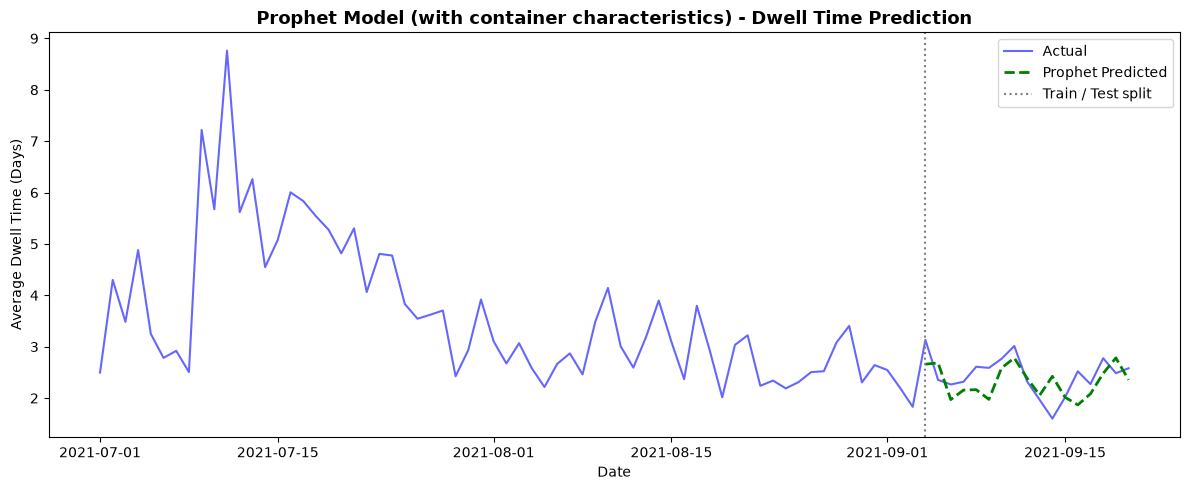

In [5]:
# ============================================
# CELL 5: Train Prophet Model (Primary) - with container characteristics
# ============================================
from prophet import Prophet
import logging
logging.getLogger('cmdstanpy').disabled = True   # hide Stan progress messages

# Unlike ARIMA (which only sees past dwell values), Prophet also uses daily container
# characteristics as extra regressors. Only information known when a container is
# discharged is used (events recorded after discharge are not used - no data leakage).
events = df.merge(dwell[['Case_ID', 'Discharge_Time']], on='Case_ID')
known_at_arrival = events[events['Timestamp'] <= events['Discharge_Time']]
arrival_flags = in_window[['Case_ID']].copy()
arrival_flags['Date'] = pd.to_datetime(in_window['Date'])
for activity, column in [('CUSTOMS_DEL', 'Customs_Share'),
                         ('HAS_QUARANTINE_FLAG', 'Quarantine_Share'),
                         ('SP_RED_WAY_PIB', 'Red_Lane_Share')]:
    flagged = known_at_arrival.loc[known_at_arrival['Activity'] == activity, 'Case_ID']
    arrival_flags[column] = arrival_flags['Case_ID'].isin(flagged).astype(int)

PROPHET_REGRESSORS = ['Customs_Share', 'Quarantine_Share', 'Red_Lane_Share', 'Arrivals']
daily_chars = arrival_flags.groupby('Date')[PROPHET_REGRESSORS[:3]].mean()
daily_chars['Arrivals'] = arrival_flags.groupby('Date').size()
daily_chars = daily_chars.reindex(daily_series.index).interpolate()

# Same series and the same split as ARIMA, plus the regressor columns
prophet_df = daily_dwell.rename(columns={'Date': 'ds', 'Avg_Dwell_Days': 'y'})
prophet_df[PROPHET_REGRESSORS] = daily_chars.values
prophet_train = prophet_df[:split]
prophet_test = prophet_df[split:]

def build_prophet(cps, mode):
    # Only ~3 months of data, so yearly seasonality is disabled
    m = Prophet(growth='linear', yearly_seasonality=False, weekly_seasonality=True,
                daily_seasonality=False, changepoint_prior_scale=cps, seasonality_mode=mode)
    for reg in PROPHET_REGRESSORS:
        m.add_regressor(reg)
    return m

def prophet_rolling(cps, mode, start, end, horizon):
    """Rolling-origin evaluation: refit at each day and forecast the next `horizon` days."""
    actual, pred = [], []
    for origin in range(start, end - horizon + 1):
        m = build_prophet(cps, mode).fit(prophet_df[:origin])
        future = prophet_df[origin:origin + horizon]
        actual.extend(future['y'].values)
        pred.extend(m.predict(future[['ds'] + PROPHET_REGRESSORS])['yhat'].clip(lower=0).values)
    return evaluate(actual, pred)

# Tune settings on a validation period taken from the TRAINING data only (last 20% of train)
val_start = int(split * 0.8)
val_scores = {}
for cps in [0.01, 0.05, 0.5]:
    for mode in ['additive', 'multiplicative']:
        val_scores[(cps, mode)] = prophet_rolling(cps, mode, val_start, split, horizon=1)[1]
PROPHET_CPS, PROPHET_MODE = min(val_scores, key=val_scores.get)
print("Validation MAE (train data only):")
for (cps, mode), score in sorted(val_scores.items(), key=lambda kv: kv[1]):
    print(f"  changepoint_prior_scale={cps:<5} mode={mode:<15} MAE={score:.3f}")
print(f"Selected: changepoint_prior_scale={PROPHET_CPS}, seasonality_mode={PROPHET_MODE}")

# Hold-out test (same 17 days as ARIMA)
model_prophet = build_prophet(PROPHET_CPS, PROPHET_MODE).fit(prophet_train)
prophet_pred = model_prophet.predict(prophet_test[['ds'] + PROPHET_REGRESSORS])['yhat'].clip(lower=0).values
prophet_rmse, prophet_mae, prophet_mape = evaluate(prophet_test['y'], prophet_pred)

# Rolling 7-day-ahead evaluation (same procedure as ARIMA)
prophet_roll_rmse, prophet_roll_mae, prophet_roll_mape = prophet_rolling(PROPHET_CPS, PROPHET_MODE, split, len(prophet_df), horizon=7)

print("=" * 50)
print("PROPHET MODEL TRAINED SUCCESSFULLY (Primary)")
print("=" * 50)
print(f"Regressors: {PROPHET_REGRESSORS}")
print(f"Hold-out test  -> RMSE: {prophet_rmse:.4f} | MAE: {prophet_mae:.4f} | MAPE: {prophet_mape:.2f}%")
print(f"Rolling 7-day  -> RMSE: {prophet_roll_rmse:.4f} | MAE: {prophet_roll_mae:.4f} | MAPE: {prophet_roll_mape:.2f}%")
print("=" * 50)

# Plot
plt.figure(figsize=(12, 5))
plt.plot(prophet_df['ds'], prophet_df['y'], label='Actual', color='blue', linewidth=1.5, alpha=0.6)
plt.plot(prophet_test['ds'].values, prophet_pred, label='Prophet Predicted', color='green', linestyle='--', linewidth=2)
plt.axvline(prophet_test['ds'].iloc[0], color='gray', linestyle=':', label='Train / Test split')
plt.title('Prophet Model (with container characteristics) - Dwell Time Prediction', fontsize=13, fontweight='bold')
plt.xlabel('Date')
plt.ylabel('Average Dwell Time (Days)')
plt.legend()
plt.tight_layout()
plt.savefig('prophet_results.png', dpi=150, bbox_inches='tight')
plt.show()

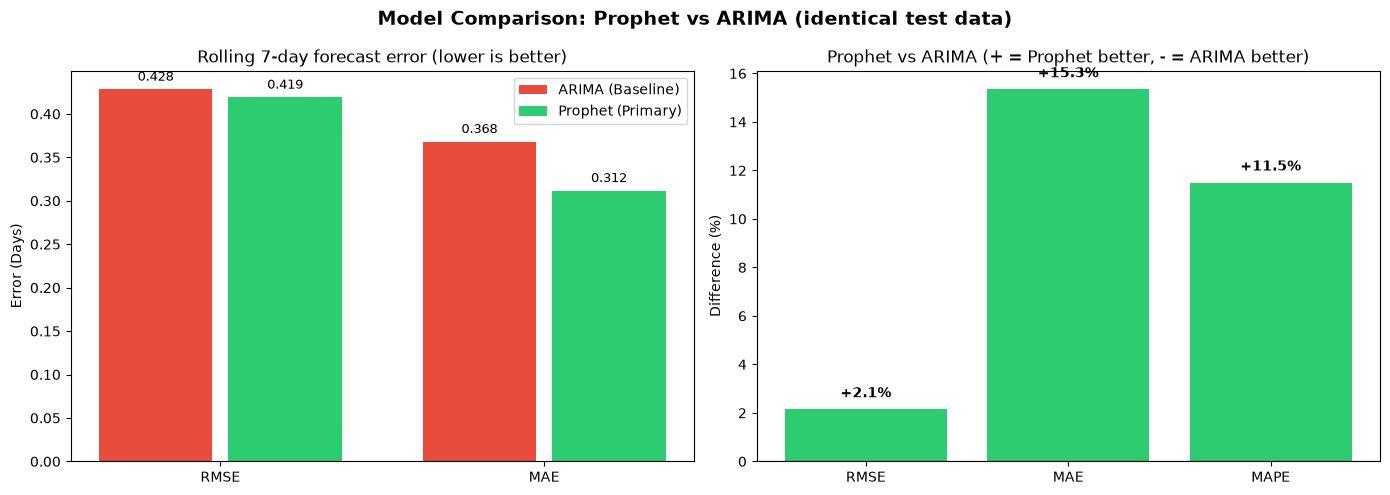

             ARIMA (hold-out)  Prophet (hold-out)  ARIMA (rolling 7d)  Prophet (rolling 7d)
RMSE (days)             0.428               0.382               0.428                 0.419
MAE (days)              0.356               0.316               0.368                 0.312
MAPE (%)               14.370              13.426              16.750                14.824

RMSE: +2.1% | MAE: +15.3% | MAPE: +11.5%  (+ = Prophet better)
Conclusion: Prophet performs better for daily dwell time forecasting on this dataset.


In [6]:
# ============================================
# CELL 6: Prophet vs ARIMA Comparison
# ============================================
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Model Comparison: Prophet vs ARIMA (identical test data)', fontsize=14, fontweight='bold')

# Bar chart comparing metrics on the rolling 7-day evaluation
metrics = ['RMSE', 'MAE']
arima_scores = [arima_roll_rmse, arima_roll_mae]
prophet_scores = [prophet_roll_rmse, prophet_roll_mae]
x = np.arange(len(metrics))
axes[0].bar(x - 0.2, arima_scores, 0.35, label='ARIMA (Baseline)', color='#e74c3c')
axes[0].bar(x + 0.2, prophet_scores, 0.35, label='Prophet (Primary)', color='#2ecc71')
axes[0].set_xticks(x)
axes[0].set_xticklabels(metrics)
axes[0].set_ylabel('Error (Days)')
axes[0].set_title('Rolling 7-day forecast error (lower is better)')
axes[0].legend()
for i, v in enumerate(arima_scores):
    axes[0].text(i - 0.2, v + 0.01, f'{v:.3f}', ha='center', fontsize=9)
for i, v in enumerate(prophet_scores):
    axes[0].text(i + 0.2, v + 0.01, f'{v:.3f}', ha='center', fontsize=9)

# Relative difference: positive = Prophet better, negative = ARIMA better
diff_rmse = ((arima_roll_rmse - prophet_roll_rmse) / arima_roll_rmse) * 100
diff_mae = ((arima_roll_mae - prophet_roll_mae) / arima_roll_mae) * 100
diff_mape = ((arima_roll_mape - prophet_roll_mape) / arima_roll_mape) * 100
diffs = [diff_rmse, diff_mae, diff_mape]
bars = axes[1].bar(['RMSE', 'MAE', 'MAPE'], diffs, color=['#2ecc71' if d > 0 else '#e74c3c' for d in diffs])
axes[1].axhline(0, color='black', linewidth=0.8)
axes[1].set_ylabel('Difference (%)')
axes[1].set_title('Prophet vs ARIMA (+ = Prophet better, - = ARIMA better)')
for bar, val in zip(bars, diffs):
    axes[1].text(bar.get_x() + bar.get_width()/2, val + (0.5 if val >= 0 else -1.5), f'{val:+.1f}%', ha='center', fontweight='bold')

plt.tight_layout()
plt.savefig('model_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

comparison = pd.DataFrame({
    'ARIMA (hold-out)': [arima_rmse, arima_mae, arima_mape],
    'Prophet (hold-out)': [prophet_rmse, prophet_mae, prophet_mape],
    'ARIMA (rolling 7d)': [arima_roll_rmse, arima_roll_mae, arima_roll_mape],
    'Prophet (rolling 7d)': [prophet_roll_rmse, prophet_roll_mae, prophet_roll_mape],
}, index=['RMSE (days)', 'MAE (days)', 'MAPE (%)']).round(3)
print(comparison.to_string())

# Decide the better model on the rolling 7-day MAE (primary decision metric)
best_dwell_model = 'Prophet' if prophet_roll_mae < arima_roll_mae else 'ARIMA'
print(f"\nRMSE: {diff_rmse:+.1f}% | MAE: {diff_mae:+.1f}% | MAPE: {diff_mape:+.1f}%  (+ = Prophet better)")
if abs(diff_mae) < 5:
    print(f"Conclusion: Prophet and ARIMA perform comparably (MAE within {abs(diff_mae):.1f}%); "
          f"{best_dwell_model} is marginally better on this dataset.")
else:
    print(f"Conclusion: {best_dwell_model} performs better for daily dwell time forecasting on this dataset.")

XGBOOST OCCUPANCY MODEL TRAINED SUCCESSFULLY (Yard Block 01)
Training days: 65 | Test days: 17
Next-day forecast -> R²: 0.8618 | RMSE: 61.3 | MAE: 48.3 containers | MAPE: 7.3%
Multi-day recursive forecast MAPE:
   1 days ahead: 7.3%  (n=17)
   3 days ahead: 11.1%  (n=15)
   7 days ahead: 10.2%  (n=11)
  10 days ahead: 11.6%  (n=8)
  14 days ahead: 6.4%  (n=4)


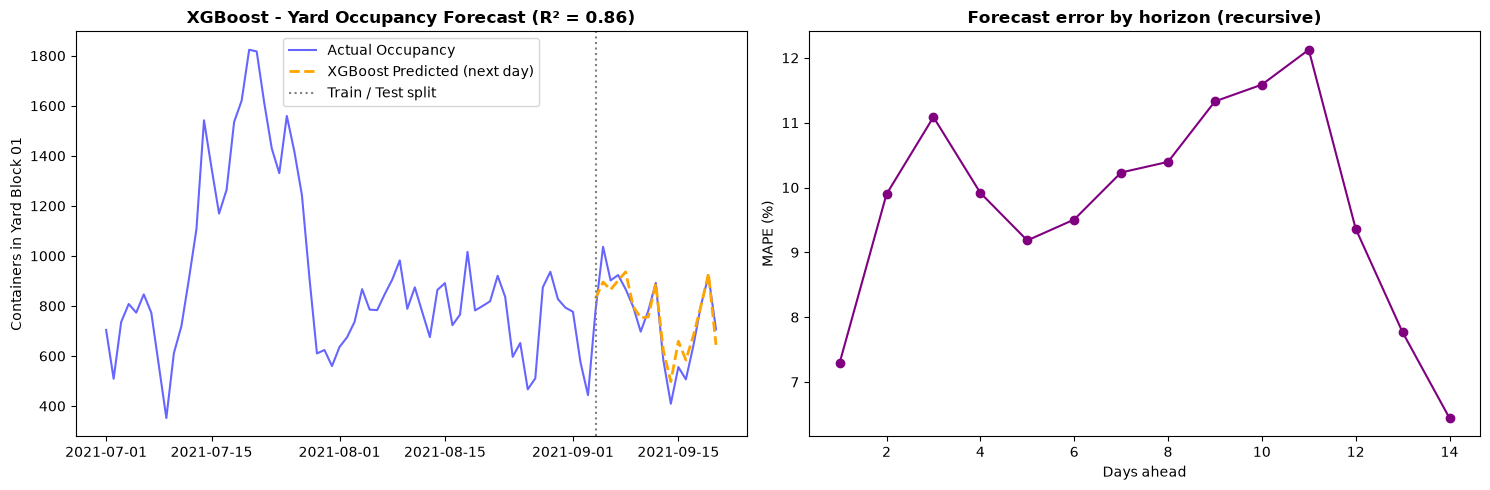

In [7]:
# ============================================
# CELL 7: Train XGBoost Model (Yard Occupancy Forecast)
# ============================================
import xgboost as xgb
from sklearn.metrics import r2_score

# Yard occupancy = number of containers physically in the yard at the end of each day
# (discharged on or before that day and not yet trucked out). Containers discharged before
# the modelling window are included, because they still occupy space inside the window.
# Yard Block 01 holds BLOCK_SHARE of the terminal's containers (Cell 2), so the block's
# occupancy and arrivals are that share of the terminal totals.
occ_days = pd.date_range(WINDOW_START - pd.Timedelta(days=20), WINDOW_END, freq='D')
end_of_day = (occ_days + pd.Timedelta(days=1)).values
dis_sorted = np.sort(dwell['Discharge_Time'].values)
out_sorted = np.sort(dwell['TruckOut_Time'].values)
occupancy_history = pd.DataFrame({
    'Occupancy': (np.searchsorted(dis_sorted, end_of_day, side='left') - np.searchsorted(out_sorted, end_of_day, side='left')) * BLOCK_SHARE,
    'Arrivals': dwell.groupby(pd.to_datetime(dwell['Date'])).size().reindex(occ_days, fill_value=0).values * BLOCK_SHARE,
}, index=occ_days)

# Features: recent occupancy + incoming container volumes. In the integrated system the
# day's arrivals come from vessel discharge plans (Component 1 - berth / vessel ETA).
OCC_FEATURES = ['Occ_Prev', 'Occ_Prev2', 'Occ_Prev7', 'Arr_Today', 'Arr_Prev1', 'Arr_Prev2', 'Arr_Prev3_7', 'DayOfWeek']

def occupancy_features(hist):
    X = pd.DataFrame(index=hist.index)
    X['Occ_Prev'] = hist['Occupancy'].shift(1)
    X['Occ_Prev2'] = hist['Occupancy'].shift(2)
    X['Occ_Prev7'] = hist['Occupancy'].shift(7)
    X['Arr_Today'] = hist['Arrivals']
    X['Arr_Prev1'] = hist['Arrivals'].shift(1)
    X['Arr_Prev2'] = hist['Arrivals'].shift(2)
    X['Arr_Prev3_7'] = hist['Arrivals'].shift(3).rolling(5).sum()
    X['DayOfWeek'] = hist.index.dayofweek
    return X[OCC_FEATURES]

occ_data = pd.concat([occupancy_features(occupancy_history), occupancy_history['Occupancy']], axis=1).dropna()
occ_data = occ_data[occ_data.index >= WINDOW_START]

# Train/Test split (80/20, chronological)
split3 = int(len(occ_data) * 0.8)
X_train, X_test = occ_data[OCC_FEATURES][:split3], occ_data[OCC_FEATURES][split3:]
y_train, y_test = occ_data['Occupancy'][:split3], occ_data['Occupancy'][split3:]

xgb_model = xgb.XGBRegressor(n_estimators=400, max_depth=3, learning_rate=0.05,
                             subsample=0.9, random_state=42)
xgb_model.fit(X_train, y_train)
xgb_pred = xgb_model.predict(X_test)

# Next-day metrics
xgb_rmse = np.sqrt(mean_squared_error(y_test, xgb_pred))
xgb_mae = mean_absolute_error(y_test, xgb_pred)
xgb_mape = np.mean(np.abs((y_test.values - xgb_pred) / y_test.values)) * 100
xgb_r2 = r2_score(y_test, xgb_pred)

def forecast_occupancy(model, hist, planned_arrivals):
    """Recursive multi-day forecast: each predicted day becomes history for the next one.
    planned_arrivals: Series indexed by future dates (incoming container projections)."""
    sim = hist[['Occupancy', 'Arrivals']].copy()
    for day, arrivals in planned_arrivals.items():
        sim.loc[day, ['Occupancy', 'Arrivals']] = [np.nan, arrivals]
        sim.loc[day, 'Occupancy'] = model.predict(occupancy_features(sim).loc[[day]])[0]
    return sim.loc[planned_arrivals.index, 'Occupancy']

# Multi-day evaluation: from every test day, forecast up to 14 days ahead recursively
horizon_errors = {}
for origin in range(split3, len(occ_data)):
    start = occ_data.index[origin]
    future_days = occ_data.index[origin:origin + 14]
    preds = forecast_occupancy(xgb_model, occupancy_history.loc[:start - pd.Timedelta(days=1)],
                               occupancy_history.loc[future_days, 'Arrivals'])
    for h, day in enumerate(future_days, start=1):
        actual = occupancy_history.loc[day, 'Occupancy']
        horizon_errors.setdefault(h, []).append(abs(actual - preds[day]) / actual * 100)
horizon_mape = {h: float(np.mean(v)) for h, v in horizon_errors.items()}

print("=" * 50)
print("XGBOOST OCCUPANCY MODEL TRAINED SUCCESSFULLY (Yard Block 01)")
print("=" * 50)
print(f"Training days: {len(X_train)} | Test days: {len(X_test)}")
print(f"Next-day forecast -> R²: {xgb_r2:.4f} | RMSE: {xgb_rmse:.1f} | MAE: {xgb_mae:.1f} containers | MAPE: {xgb_mape:.1f}%")
print("Multi-day recursive forecast MAPE:")
for h in [1, 3, 7, 10, 14]:
    if h in horizon_mape:
        print(f"  {h:>2} days ahead: {horizon_mape[h]:.1f}%  (n={len(horizon_errors[h])})")
print("=" * 50)

# Plot
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].plot(occ_data.index, occ_data['Occupancy'], label='Actual Occupancy', color='blue', linewidth=1.5, alpha=0.6)
axes[0].plot(y_test.index, xgb_pred, label='XGBoost Predicted (next day)', color='orange', linestyle='--', linewidth=2)
axes[0].axvline(y_test.index[0], color='gray', linestyle=':', label='Train / Test split')
axes[0].set_title(f'XGBoost - Yard Occupancy Forecast (R² = {xgb_r2:.2f})', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Containers in Yard Block 01')
axes[0].legend()
hs = sorted(horizon_mape)
axes[1].plot(hs, [horizon_mape[h] for h in hs], 'o-', color='purple')
axes[1].set_title('Forecast error by horizon (recursive)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Days ahead')
axes[1].set_ylabel('MAPE (%)')
plt.tight_layout()
plt.savefig('xgboost_results.png', dpi=150, bbox_inches='tight')
plt.show()

PER-CONTAINER DWELL MODEL TRAINED SUCCESSFULLY
Training containers: 68,204 | Test containers: 17,051
XGBoost   -> MAE: 1.356 days | RMSE: 2.107 days | R²: 0.293
Baseline  -> MAE: 1.728 days | RMSE: 2.506 days  (median for every container)
MAE improvement over baseline: 21.5%


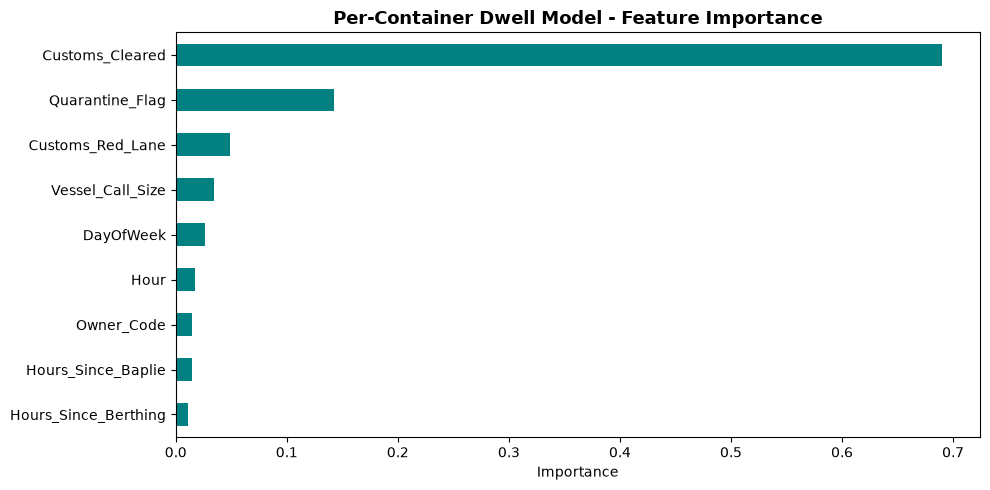

In [8]:
# ============================================
# CELL 7B: Per-Container Dwell Time Model (XGBoost)
# ============================================
# Prophet/ARIMA forecast the DAILY AVERAGE dwell time, so every container arriving on the
# same day would get the same prediction. This model predicts dwell time for each
# individual container, using only information known when the container is discharged
# (events recorded after discharge are not used, to avoid data leakage).

# events / known_at_arrival are built in Cell 5
first_event = lambda activity: events[events['Activity'] == activity].groupby('Case_ID')['Timestamp'].first()

containers = in_window.set_index('Case_ID').copy()

# Owner / shipping line code = first 4 letters of the container number (e.g. MSKU = Maersk)
containers['Owner_Code'] = containers.index.str[:4]
TOP_OWNERS = containers['Owner_Code'].value_counts().index[:25].tolist()
containers['Owner_Code'] = containers['Owner_Code'].where(containers['Owner_Code'].isin(TOP_OWNERS), 'OTHER')

# Vessel / stowage plan timing
containers['Hours_Since_Baplie'] = (containers['Discharge_Time'] - first_event('BAPLIE').reindex(containers.index)).dt.total_seconds() / 3600
containers['Hours_Since_Berthing'] = (containers['Discharge_Time'] - first_event('VESSEL_ATB').reindex(containers.index)).dt.total_seconds() / 3600
berthing = first_event('VESSEL_ATB').reindex(containers.index)
containers['Vessel_Call_Size'] = berthing.map(berthing.value_counts())

# Cargo / clearance status known at arrival
for activity, column in [('CUSTOMS_DEL', 'Customs_Cleared'),
                         ('HAS_QUARANTINE_FLAG', 'Quarantine_Flag'),
                         ('SP_RED_WAY_PIB', 'Customs_Red_Lane')]:
    containers[column] = containers.index.isin(known_at_arrival.loc[known_at_arrival['Activity'] == activity, 'Case_ID']).astype(int)

DWELL_FEATURES = ['Owner_Code', 'Hour', 'DayOfWeek', 'Hours_Since_Baplie', 'Hours_Since_Berthing',
                  'Vessel_Call_Size', 'Customs_Cleared', 'Quarantine_Flag', 'Customs_Red_Lane']
containers = containers.sort_values('Discharge_Time')
containers['Owner_Code'] = pd.Categorical(containers['Owner_Code'], categories=TOP_OWNERS + ['OTHER'])

# Chronological 80/20 split
split4 = int(len(containers) * 0.8)
c_train, c_test = containers[:split4], containers[split4:]

dwell_model = xgb.XGBRegressor(n_estimators=500, max_depth=6, learning_rate=0.05, subsample=0.8,
                               colsample_bytree=0.8, enable_categorical=True, tree_method='hist', random_state=42)
dwell_model.fit(c_train[DWELL_FEATURES], np.log1p(c_train['Dwell_Days']))   # log target: dwell is right-skewed
c_pred = np.expm1(dwell_model.predict(c_test[DWELL_FEATURES])).clip(min=0)

# Baseline: give every container the training median dwell time
baseline_pred = np.full(len(c_test), c_train['Dwell_Days'].median())
cd_rmse, cd_mae, _ = evaluate(c_test['Dwell_Days'], c_pred)
cb_rmse, cb_mae, _ = evaluate(c_test['Dwell_Days'], baseline_pred)
cd_r2 = r2_score(c_test['Dwell_Days'], c_pred)

print("=" * 50)
print("PER-CONTAINER DWELL MODEL TRAINED SUCCESSFULLY")
print("=" * 50)
print(f"Training containers: {len(c_train):,} | Test containers: {len(c_test):,}")
print(f"XGBoost   -> MAE: {cd_mae:.3f} days | RMSE: {cd_rmse:.3f} days | R²: {cd_r2:.3f}")
print(f"Baseline  -> MAE: {cb_mae:.3f} days | RMSE: {cb_rmse:.3f} days  (median for every container)")
print(f"MAE improvement over baseline: {(cb_mae - cd_mae) / cb_mae * 100:.1f}%")
print("=" * 50)

importance = pd.Series(dwell_model.feature_importances_, index=DWELL_FEATURES).sort_values()
plt.figure(figsize=(10, 5))
importance.plot(kind='barh', color='teal')
plt.title('Per-Container Dwell Model - Feature Importance', fontsize=13, fontweight='bold')
plt.xlabel('Importance')
plt.tight_layout()
plt.savefig('dwell_feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()

COLOMBO DATASET LOADED
Total containers: 2,000
Container type mix: {'DRY': 63.3, 'REEFER': 18.6, 'HAZMAT': 14.1, 'OVERSIZED': 4.0}

Zones of Yard Block 01 (sections of the block, from the gate end):
  Fast-Access    YB01_FAST     Bays nearest the gate, for short-stay containers
  Medium-Access  YB01_MEDIUM   Middle bays, for medium-stay containers
  Long-Term      YB01_LONG     Far bays, for long-stay containers
  Reefer         YB01_REEFER   Powered bays for refrigerated containers
  Hazardous      YB01_HAZARD   Isolated bays for dangerous cargo, behind a buffer

ZONE RECOMMENDATIONS FOR 17,051 TEST CONTAINERS:
Recommended_Zone
Fast-Access      7214
Medium-Access    4185
Reefer           3234
Hazardous        2414
Long-Term           4

DRY/OVERSIZED containers placed in the zone their ACTUAL dwell needed: 72.4%
  (baseline - always Fast-Access: 72.8%)
  Reefer/hazmat containers always go to their special zone of the block (yard-type rule).


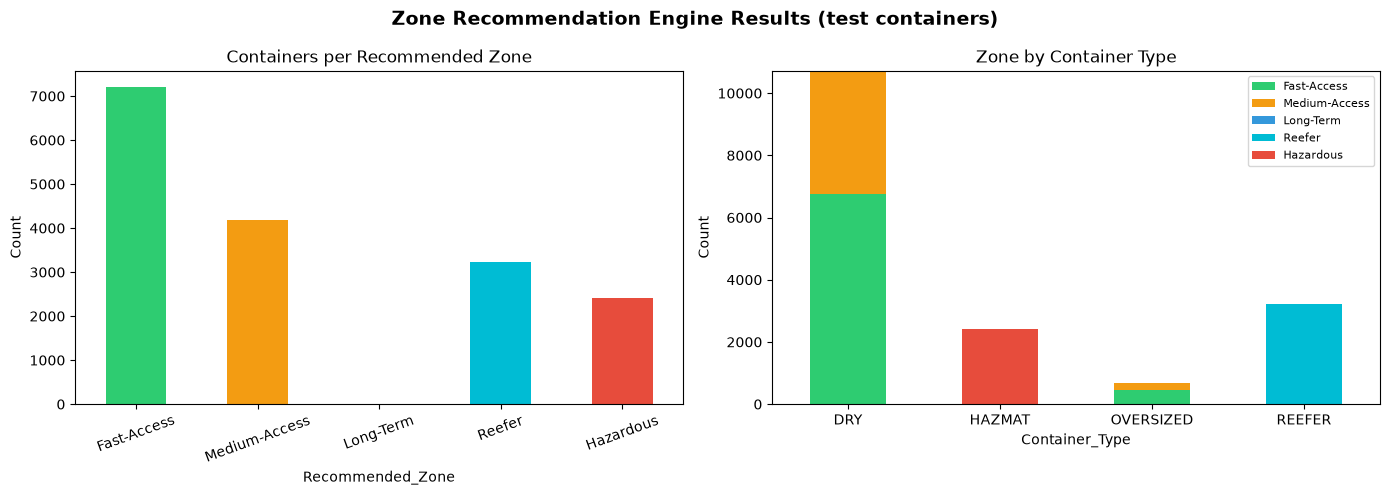

In [9]:
# ============================================
# CELL 8: Zone Recommendation Engine
# ============================================
# The engine lives in backend/yard/zone_engine.py so the notebook, the simulation (Cell 9)
# and the Flask API all use exactly the same rules:
#   1. Dwell class (FR04): Short-stay < 3 days, Medium-stay 3-7 days, Long-stay > 7 days
#   2. Yard-type check (FR05): REEFER -> Reefer yard, HAZMAT -> Hazardous yard
#   3. Zone (FR06): Fast-Access / Medium-Access / Long-Term by dwell class
import sys
import os
sys.path.insert(0, os.path.abspath('../backend/yard'))
from zone_engine import (ZONES, DWELL_CLASS_ZONE, SPECIAL_TYPE_ZONE, SECTION_ZONE, TIER_HEIGHT, ROWS_PER_BAY,
                         BLOCK_NAME, block_layout, classify_dwell, recommend_zone, YardState)

# Colombo Port container data: used for the container TYPE mix (it has no departure times,
# so it cannot be used for dwell time)
colombo = pd.read_csv(r"C:\Users\CYBORG 15\Downloads\container_yard_data.csv")
type_mix = colombo['Container_Type'].value_counts(normalize=True)

print("=" * 60)
print("COLOMBO DATASET LOADED")
print("=" * 60)
print(f"Total containers: {len(colombo):,}")
print(f"Container type mix: {(type_mix * 100).round(1).to_dict()}")
print(f"\nZones of {BLOCK_NAME} (sections of the block, from the gate end):")
for zone, info in ZONES.items():
    print(f"  {zone:<14} {info['section']:<13} {info['description']}")

# Apply the engine to the TEST containers using the per-container model's PREDICTED dwell.
# Kaggle does not record container type, so types follow the Colombo mix.
zone_demo = pd.DataFrame({
    'Container_Type': np.random.default_rng(0).choice(type_mix.index, size=len(c_test), p=type_mix.values),
    'Predicted_Dwell': c_pred,
    'Actual_Dwell': c_test['Dwell_Days'].values,
})
zone_demo['Recommended_Zone'] = [recommend_zone(t, d)['zone'] for t, d in zip(zone_demo['Container_Type'], zone_demo['Predicted_Dwell'])]
zone_demo['Ideal_Zone'] = [recommend_zone(t, d)['zone'] for t, d in zip(zone_demo['Container_Type'], zone_demo['Actual_Dwell'])]

# How often the zone from the PREDICTED dwell matches the zone the ACTUAL dwell would need
general = ~zone_demo['Container_Type'].isin(SPECIAL_TYPE_ZONE)
zone_match = (zone_demo.loc[general, 'Recommended_Zone'] == zone_demo.loc[general, 'Ideal_Zone']).mean() * 100
majority_match = (zone_demo.loc[general, 'Ideal_Zone'] == 'Fast-Access').mean() * 100

print(f"\nZONE RECOMMENDATIONS FOR {len(zone_demo):,} TEST CONTAINERS:")
print(zone_demo['Recommended_Zone'].value_counts().to_string())
print(f"\nDRY/OVERSIZED containers placed in the zone their ACTUAL dwell needed: {zone_match:.1f}%")
print(f"  (baseline - always Fast-Access: {majority_match:.1f}%)")
print("  Reefer/hazmat containers always go to their special zone of the block (yard-type rule).")

# Visualization
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Zone Recommendation Engine Results (test containers)', fontsize=14, fontweight='bold')
zone_order = list(ZONES)
zone_demo['Recommended_Zone'].value_counts().reindex(zone_order, fill_value=0).plot(
    kind='bar', ax=axes[0], color=['#2ecc71', '#f39c12', '#3498db', '#00bcd4', '#e74c3c'])
axes[0].set_title('Containers per Recommended Zone')
axes[0].set_ylabel('Count')
axes[0].tick_params(axis='x', rotation=20)
zone_demo.groupby(['Container_Type', 'Recommended_Zone']).size().unstack(fill_value=0).reindex(columns=zone_order, fill_value=0).plot(
    kind='bar', ax=axes[1], stacked=True, color=['#2ecc71', '#f39c12', '#3498db', '#00bcd4', '#e74c3c'])
axes[1].set_title('Zone by Container Type')
axes[1].set_ylabel('Count')
axes[1].tick_params(axis='x', rotation=0)
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.savefig('zone_recommendation.png', dpi=150, bbox_inches='tight')
plt.show()

Validation (3,354 containers in the block) - random placement: 3,132 reshuffles
  AI rule=best_fit     margin= 0h ->  3,791 reshuffles (-21.0% vs random)


  AI rule=empty_first  margin= 0h ->  2,081 reshuffles (+33.6% vs random)
  AI rule=empty_first  margin=12h ->  1,862 reshuffles (+40.5% vs random)


  AI rule=empty_first  margin=24h ->  1,834 reshuffles (+41.4% vs random)


  AI rule=empty_first  margin=36h ->  1,824 reshuffles (+41.8% vs random)
Selected on validation: rule=empty_first, margin=36h



YARD STACKING SIMULATION RESULTS - YARD BLOCK 01 (TEST CONTAINERS)
Containers simulated: ~4,237 per run = 25% of 17,051 test containers (real Kaggle arrivals/departures)
Container type mix (Colombo): {'DRY': 63.3, 'REEFER': 18.6, 'HAZMAT': 14.1, 'OVERSIZED': 4.0}
Yard Block 01: 56 bays x 6 rows = 324 stacks x 4 tiers (peak occupancy 930 = 75% full) | 5 runs

                          Random placement  AI (predicted dwell)  AI (perfect knowledge)
reshuffles                        3831.600              2085.400                1470.800
reshuffles_per_retrieval             0.904                 0.492                   0.347
blocked_retrieval_pct               55.654                36.900                  21.477
type_violations                   1166.400                 0.000                   0.000
misused_special_slots              931.000                 0.000                   0.000

Reshuffles (mean ± std over 5 runs):
  Random placement             3,832 ± 186
  AI (predicted dwell)  

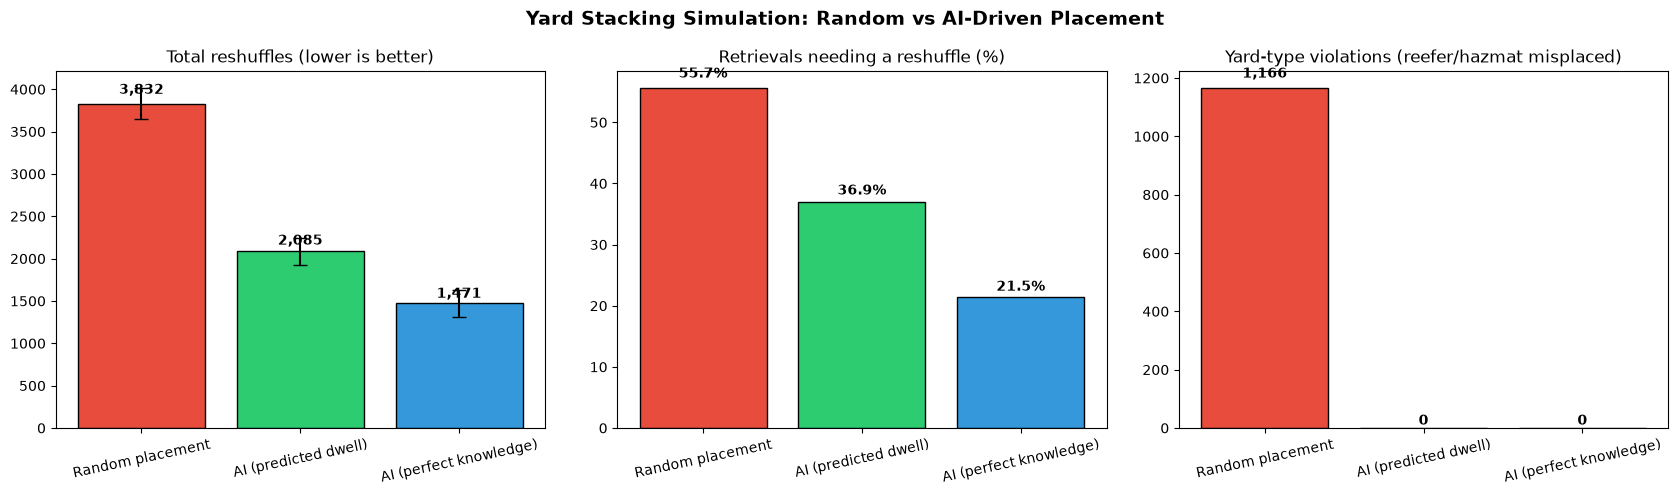

In [10]:
# ============================================
# CELL 9: Yard Stacking Simulation - Random vs AI-Driven Placement
# ============================================
# Containers: REAL discharge and truck-out times from the Kaggle log. The AI only sees the
# PREDICTED dwell time from the per-container model (Cell 7B), never the real departure.
# Container types: the Kaggle log does not record type, so each container is assigned a
# type following the Colombo Port mix (container_yard_data.csv, Cell 8).
# Yard: ONE yard block (Yard Block 01) - bays x 6 rows x 4 tiers, each zone a range of bays.
# The block receives BLOCK_SHARE of the containers (Cell 2): a random share is drawn per run.
# Placement uses the same zone engine as the API (backend/yard/zone_engine.py, Cell 8).
# Reshuffle = a container that must be moved because it sits on top of the one being retrieved.
import random

YARD_FILL_AT_PEAK = 0.75                          # yard sized so that peak occupancy = 75% full
type_mix = colombo['Container_Type'].value_counts(normalize=True)

def class_shares(dwell_days, floor=0.03):
    counts = pd.Series([classify_dwell(d) for d in dwell_days]).value_counts(normalize=True)
    shares = {c: max(counts.get(c, 0), floor) for c in ['Short-stay', 'Medium-stay', 'Long-stay']}
    return {c: v / sum(shares.values()) for c, v in shares.items()}

def yard_layout(total_slots, zone_shares):
    """Bay ranges of the block: reefer/hazardous zones from the Colombo type mix, the general
    zones by dwell-class share. Returns {section: {'first_bay', 'bays', 'rows'}}."""
    general = type_mix.get('DRY', 0) + type_mix.get('OVERSIZED', 0)
    zone_share = {zone: general * zone_shares[cls] for cls, zone in DWELL_CLASS_ZONE.items()}
    zone_share['Reefer'] = type_mix.get('REEFER', 0)
    zone_share['Hazardous'] = type_mix.get('HAZMAT', 0)
    return block_layout({zone: round(total_slots * share / TIER_HEIGHT) for zone, share in zone_share.items()})

def block_sample(n, seed):
    """Which containers go to Yard Block 01 (a random BLOCK_SHARE of them)."""
    return np.random.default_rng(1000 + seed).random(n) < BLOCK_SHARE

def run_simulation(arrival, departure, predicted_dwell, types, zone_shares, strategy, seed,
                   rule='empty_first', margin_h=24):
    """strategy: 'random' (current practice) or 'ai' (zone engine). Uses zone_engine.YardState."""
    rng = random.Random(seed)
    arr_h = arrival.astype('datetime64[s]').astype(np.int64) / 3600
    dep_h = departure.astype('datetime64[s]').astype(np.int64) / 3600
    pred_dep_h = arr_h + predicted_dwell * 24
    a_sorted, d_sorted = np.sort(arr_h), np.sort(dep_h)
    peak = int(max(np.searchsorted(a_sorted, t, 'right') - np.searchsorted(d_sorted, t, 'right') for t in a_sorted))
    layout = yard_layout(int(peak / YARD_FILL_AT_PEAK), zone_shares)
    yard = YardState(layout, TIER_HEIGHT, rule=rule, margin_h=margin_h)

    def place(cid):
        return yard.place(cid, types[cid], predicted_dwell[cid], pred_dep_h[cid], strategy, rng)

    events = sorted([(t, 0, cid) for cid, t in enumerate(dep_h)] + [(t, 1, cid) for cid, t in enumerate(arr_h)])
    reshuffles = retrievals = blocked = violations = misused_special = 0
    for t, kind, cid in events:                   # departures before arrivals at the same time
        if kind == 1:
            if place(cid) is None:
                continue
            zone = SECTION_ZONE[yard.section_of(cid)]
            needed = SPECIAL_TYPE_ZONE.get(types[cid])
            if needed and zone != needed:
                violations += 1                   # reefer without power / hazmat not isolated
            elif not needed and zone in SPECIAL_TYPE_ZONE.values():
                misused_special += 1              # ordinary container taking a special slot
        elif cid in yard.location:
            above = yard.retrieve(cid)
            retrievals += 1
            blocked += bool(above)
            for moved in above:                   # each blocking container is relocated
                reshuffles += 1
                place(moved)
    return {'reshuffles': reshuffles, 'reshuffles_per_retrieval': reshuffles / max(retrievals, 1),
            'blocked_retrieval_pct': blocked / max(retrievals, 1) * 100,
            'type_violations': violations, 'misused_special_slots': misused_special,
            'stacks': len(yard.stacks), 'bays': yard.bay_count, 'containers': len(arr_h),
            'peak_occupancy': peak, 'layout': layout}

# ---------------------------------------------------------------------------------
# STEP 1 - Choose the AI stacking rule on a VALIDATION period (training data only)
# A model trained on the first 80% of the training containers predicts the last 20%.
# ---------------------------------------------------------------------------------
val_cut = int(len(c_train) * 0.8)
c_fit, c_val = c_train[:val_cut], c_train[val_cut:]
val_model = xgb.XGBRegressor(**dwell_model.get_params()).fit(c_fit[DWELL_FEATURES], np.log1p(c_fit['Dwell_Days']))
val_pred = np.expm1(val_model.predict(c_val[DWELL_FEATURES])).clip(min=0)
val_shares = class_shares(np.expm1(val_model.predict(c_fit[DWELL_FEATURES])))   # size zones by what the model predicts
in_block = block_sample(len(c_val), 100)
val_types = np.random.default_rng(100).choice(type_mix.index, size=in_block.sum(), p=type_mix.values)
val_args = (c_val['Discharge_Time'].values[in_block], c_val['TruckOut_Time'].values[in_block],
            val_pred[in_block], val_types, val_shares)

val_random = run_simulation(*val_args, 'random', seed=100)['reshuffles']
print(f"Validation ({in_block.sum():,} containers in the block) - random placement: {val_random:,} reshuffles")
val_results = {}
for rule, margin in [('best_fit', 0), ('empty_first', 0), ('empty_first', 12), ('empty_first', 24), ('empty_first', 36)]:
    r = run_simulation(*val_args, 'ai', seed=100, rule=rule, margin_h=margin)['reshuffles']
    val_results[(rule, margin)] = r
    print(f"  AI rule={rule:<12} margin={margin:>2}h -> {r:>6,} reshuffles ({(val_random - r) / val_random * 100:+.1f}% vs random)")
AI_RULE, AI_MARGIN = min(val_results, key=val_results.get)
print(f"Selected on validation: rule={AI_RULE}, margin={AI_MARGIN}h\n")

# ---------------------------------------------------------------------------------
# STEP 2 - Final evaluation on the TEST containers (run once with the selected rule)
# ---------------------------------------------------------------------------------
N_RUNS = 5                                        # different seeds for container types / random placement
test_shares = class_shares(np.expm1(dwell_model.predict(c_train[DWELL_FEATURES])))
results = {'Random placement': [], 'AI (predicted dwell)': [], 'AI (perfect knowledge)': []}
for seed in range(N_RUNS):
    in_block = block_sample(len(c_test), seed)        # the same containers for all three strategies
    types = np.random.default_rng(seed).choice(type_mix.index, size=in_block.sum(), p=type_mix.values)
    args = (c_test['Discharge_Time'].values[in_block], c_test['TruckOut_Time'].values[in_block])
    predicted, actual_dwell = c_pred[in_block], c_test['Dwell_Days'].values[in_block]
    results['Random placement'].append(run_simulation(*args, predicted, types, test_shares, 'random', seed))
    results['AI (predicted dwell)'].append(run_simulation(*args, predicted, types, test_shares, 'ai', seed, AI_RULE, AI_MARGIN))
    results['AI (perfect knowledge)'].append(run_simulation(*args, actual_dwell, types, class_shares(actual_dwell), 'ai', seed, AI_RULE, AI_MARGIN))

metrics = ['reshuffles', 'reshuffles_per_retrieval', 'blocked_retrieval_pct', 'type_violations', 'misused_special_slots']
summary = pd.DataFrame({name: {m: np.mean([r[m] for r in runs]) for m in metrics} for name, runs in results.items()}).round(3)
reshuffle_std = {name: float(np.std([r['reshuffles'] for r in runs])) for name, runs in results.items()}

random_reshuffles = summary.loc['reshuffles', 'Random placement']
ai_reshuffles = summary.loc['reshuffles', 'AI (predicted dwell)']
reshuffle_reduction = (random_reshuffles - ai_reshuffles) / random_reshuffles * 100
oracle_reduction = (random_reshuffles - summary.loc['reshuffles', 'AI (perfect knowledge)']) / random_reshuffles * 100

print("=" * 60)
print("YARD STACKING SIMULATION RESULTS - YARD BLOCK 01 (TEST CONTAINERS)")
print("=" * 60)
containers_per_run = int(np.mean([r['containers'] for r in results['Random placement']]))
print(f"Containers simulated: ~{containers_per_run:,} per run = {BLOCK_SHARE:.0%} of {len(c_test):,} test containers "
      f"(real Kaggle arrivals/departures)")
print(f"Container type mix (Colombo): {(type_mix * 100).round(1).to_dict()}")
print(f"{BLOCK_NAME}: {results['Random placement'][0]['bays']} bays x {ROWS_PER_BAY} rows = "
      f"{results['Random placement'][0]['stacks']:,} stacks x {TIER_HEIGHT} tiers "
      f"(peak occupancy {results['Random placement'][0]['peak_occupancy']:,} = {YARD_FILL_AT_PEAK:.0%} full) | {N_RUNS} runs\n")
print(summary.to_string())
print(f"\nReshuffles (mean ± std over {N_RUNS} runs):")
for name in results:
    print(f"  {name:<24} {summary.loc['reshuffles', name]:>9,.0f} ± {reshuffle_std[name]:,.0f}")
print(f"\nReshuffle reduction with AI (predicted dwell): {reshuffle_reduction:.1f}%  (proposal target: >= 25%)")
print(f"Upper bound with perfect dwell knowledge:      {oracle_reduction:.1f}%")
print(f"Yard-type violations: random {summary.loc['type_violations', 'Random placement']:,.0f} "
      f"vs AI {summary.loc['type_violations', 'AI (predicted dwell)']:,.0f}")
print("=" * 60)

# Values used by the API (Cell 12) - yard layout of the test simulation is reused by the API
sim_yard_layout = results['AI (predicted dwell)'][0]['layout']
random_accuracy = 100 - summary.loc['blocked_retrieval_pct', 'Random placement']
ai_accuracy = 100 - summary.loc['blocked_retrieval_pct', 'AI (predicted dwell)']

# Visualization
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
fig.suptitle('Yard Stacking Simulation: Random vs AI-Driven Placement', fontsize=14, fontweight='bold')
names = list(results)
colors = ['#e74c3c', '#2ecc71', '#3498db']
panels = [('reshuffles', 'Total reshuffles (lower is better)', '{:,.0f}'),
          ('blocked_retrieval_pct', 'Retrievals needing a reshuffle (%)', '{:.1f}%'),
          ('type_violations', 'Yard-type violations (reefer/hazmat misplaced)', '{:,.0f}')]
for ax, (metric, title, fmt) in zip(axes, panels):
    vals = [summary.loc[metric, n] for n in names]
    err = [reshuffle_std[n] for n in names] if metric == 'reshuffles' else None
    ax.bar(names, vals, yerr=err, color=colors, edgecolor='black', capsize=5)
    ax.set_title(title)
    ax.tick_params(axis='x', rotation=12)
    for i, v in enumerate(vals):
        ax.text(i, v * 1.02 + max(vals) * 0.01, fmt.format(v), ha='center', fontweight='bold')
plt.tight_layout()
plt.savefig('reshuffling_simulation.png', dpi=150, bbox_inches='tight')
plt.show()

In [11]:
# ============================================
# CELL 10: LIVE PREDICTION TEST - Prophet + Zone Engine + Slot Assignment
# ============================================
print("=" * 60)
print("🚢 SMART YARD ALLOCATION - LIVE PREDICTION TEST")
print("=" * 60)

# Step 1: Prophet refit on the full modelling window, forecasting the next 7 days.
# Future container characteristics would come from pre-arrival documents / vessel manifests
# (Component 1); here the average per weekday is used as a projection.
prophet_live = build_prophet(PROPHET_CPS, PROPHET_MODE).fit(prophet_df)
future = prophet_live.make_future_dataframe(periods=7, freq='D', include_history=False)
weekday_chars = prophet_df.groupby(prophet_df['ds'].dt.dayofweek)[PROPHET_REGRESSORS].mean()
future[PROPHET_REGRESSORS] = weekday_chars.reindex(future['ds'].dt.dayofweek).values
future_predictions = prophet_live.predict(future)[['ds', 'yhat']]
future_predictions['yhat'] = future_predictions['yhat'].clip(lower=0)
future_predictions.columns = ['Date', 'Predicted_Dwell_Days']

print("\n📊 Predicted Dwell Times for Next 7 Days:")
print("-" * 45)
for _, row in future_predictions.iterrows():
    print(f"  {row['Date'].strftime('%Y-%m-%d')} → {row['Predicted_Dwell_Days']:.2f} days")

# Step 2: Zone recommendation for different container types
print("\n" + "=" * 60)
print("📍 ZONE RECOMMENDATION TEST")
print("=" * 60)
test_cases = [(1.5, 'DRY'), (5.0, 'DRY'), (10.0, 'DRY'), (3.0, 'REEFER'), (2.0, 'HAZMAT'), (4.0, 'OVERSIZED')]
print(f"\n  {'Type':<11} {'Dwell':<7} {'Class':<12} {'Zone':<14} Reason")
print("-" * 100)
for test_dwell, ctype in test_cases:
    rec = recommend_zone(ctype, test_dwell)
    print(f"  {ctype:<11} {test_dwell:<7.1f} {rec['dwell_class']:<12} {rec['zone']:<14} {rec['reason']}")

# Step 3: Full pipeline - new containers arrive, get a zone AND a specific slot
print("\n" + "=" * 60)
print("🔄 FULL PIPELINE TEST - NEW CONTAINER ARRIVALS (with slot assignment)")
print("=" * 60)
avg_predicted = future_predictions['Predicted_Dwell_Days'].iloc[0]
print(f"\n  Prophet predicts tomorrow's average dwell: {avg_predicted:.2f} days")
live_yard = YardState(sim_yard_layout, TIER_HEIGHT, rule=AI_RULE, margin_h=AI_MARGIN)
for k, ctype in enumerate(['DRY', 'REEFER', 'HAZMAT', 'OVERSIZED', 'DRY']):
    rec = recommend_zone(ctype, avg_predicted)
    slot = live_yard.place(f'NEW{k + 1:03d}', ctype, avg_predicted, avg_predicted * 24)
    print(f"  {ctype:<10} → {rec['zone']:<14} slot {slot}")

print("\n✅ MODEL IS WORKING! Ready for Flask API integration.")

🚢 SMART YARD ALLOCATION - LIVE PREDICTION TEST



📊 Predicted Dwell Times for Next 7 Days:
---------------------------------------------
  2021-09-21 → 2.45 days
  2021-09-22 → 2.20 days
  2021-09-23 → 2.00 days
  2021-09-24 → 2.61 days
  2021-09-25 → 2.72 days
  2021-09-26 → 2.72 days
  2021-09-27 → 2.19 days

📍 ZONE RECOMMENDATION TEST

  Type        Dwell   Class        Zone           Reason
----------------------------------------------------------------------------------------------------
  DRY         1.5     Short-stay   Fast-Access    Predicted dwell 1.5 days (Short-stay) - bays nearest the gate, for short-stay containers
  DRY         5.0     Medium-stay  Medium-Access  Predicted dwell 5.0 days (Medium-stay) - middle bays, for medium-stay containers
  DRY         10.0    Long-stay    Long-Term      Predicted dwell 10.0 days (Long-stay) - far bays, for long-stay containers
  REEFER      3.0     Medium-stay  Reefer         Reefer container - powered bays for refrigerated containers (yard-type rule applies regardless of the 3.0

In [12]:
# ============================================
# CELL 11: TEST XGBOOST - OCCUPANCY PREDICTION
# ============================================
print("=" * 60)
print("📈 XGBOOST YARD OCCUPANCY PREDICTION TEST")
print("=" * 60)

# Show stored model metrics
print(f"\n📏 Model Performance (next-day forecast):")
print(f"  R² Score: {xgb_r2:.4f}")
print(f"  RMSE: {xgb_rmse:.2f} containers")
print(f"  MAE: {xgb_mae:.2f} containers")
print(f"  MAPE: {xgb_mape:.1f}%")

# Show some predictions vs actual
print(f"\n📊 Sample Predictions vs Actual:")
print("-" * 50)
print(f"  {'Predicted':<15} {'Actual':<15} {'Difference'}")
print("-" * 50)
for pred, actual in zip(xgb_pred[-5:], y_test.values[-5:]):
    diff = pred - actual
    print(f"  {pred:<15.0f} {actual:<15.0f} {diff:+.0f}")

# 14-day forecast from the end of the data. Incoming volumes would come from vessel
# schedules (Component 1); here the average arrivals per weekday are used as projection.
weekday_arrivals = occupancy_history.loc[WINDOW_START:, 'Arrivals'].groupby(occupancy_history.loc[WINDOW_START:].index.dayofweek).mean()
future_days = pd.date_range(WINDOW_END + pd.Timedelta(days=1), periods=14, freq='D')
planned = pd.Series(weekday_arrivals.reindex(future_days.dayofweek).values, index=future_days)
forecast_14 = forecast_occupancy(xgb_model, occupancy_history, planned)
print(f"\n📅 14-day occupancy forecast:")
for day, value in forecast_14.items():
    print(f"  {day.date()} → {value:,.0f} containers")

print(f"\n✅ XGBoost occupancy model verified!")

📈 XGBOOST YARD OCCUPANCY PREDICTION TEST

📏 Model Performance (next-day forecast):
  R² Score: 0.8618
  RMSE: 61.25 containers
  MAE: 48.30 containers
  MAPE: 7.3%

📊 Sample Predictions vs Actual:
--------------------------------------------------
  Predicted       Actual          Difference
--------------------------------------------------
  584             506             +77
  682             642             +41
  800             803             -3
  929             919             +10
  644             706             -62

📅 14-day occupancy forecast:
  2021-09-21 → 733 containers
  2021-09-22 → 800 containers
  2021-09-23 → 689 containers
  2021-09-24 → 720 containers
  2021-09-25 → 842 containers
  2021-09-26 → 910 containers
  2021-09-27 → 808 containers
  2021-09-28 → 811 containers
  2021-09-29 → 792 containers
  2021-09-30 → 710 containers
  2021-10-01 → 732 containers
  2021-10-02 → 866 containers
  2021-10-03 → 932 containers
  2021-10-04 → 821 containers

✅ XGBoost occupa

In [13]:

# CELL 12: SAVE TRAINED MODELS FOR FLASK API

import joblib
import json
import os

# Create folder to save models
save_path = '../backend/yard/models'
os.makedirs(save_path, exist_ok=True)

# Prophet and ARIMA were evaluated on the train/test split above. For deployment they are
# refit on the full modelling window so forecasts start from the most recent data.
prophet_full = prophet_live   # refit on the full window in Cell 10
joblib.dump(prophet_full, f'{save_path}/prophet_model.pkl')
print("✅ Prophet model saved!")

arima_full = ARIMA(daily_dwell['Avg_Dwell_Days'].values, order=ARIMA_ORDER).fit()
joblib.dump(arima_full, f'{save_path}/arima_model.pkl')
print("✅ ARIMA model saved!")

# Save XGBoost occupancy model + recent history (needed for recursive forecasts)
joblib.dump(xgb_model, f'{save_path}/xgboost_model.pkl')
occupancy_history.to_csv(f'{save_path}/occupancy_history.csv', index_label='Date')
print("✅ XGBoost occupancy model saved!")

# Save per-container dwell model
joblib.dump({'model': dwell_model, 'features': DWELL_FEATURES, 'owner_codes': TOP_OWNERS},
            f'{save_path}/dwell_container_model.pkl')
print("✅ Per-container dwell model saved!")

# Prophet config: regressors + weekday projection of their values for future dates
weekday_chars = prophet_df.groupby(prophet_df['ds'].dt.dayofweek)[PROPHET_REGRESSORS].mean()
prophet_config = {'growth': 'linear', 'floor': 0, 'regressors': PROPHET_REGRESSORS,
                  'weekday_regressor_projection': {int(k): v for k, v in weekday_chars.to_dict('index').items()}}
joblib.dump(prophet_config, f'{save_path}/prophet_config.pkl')
print("✅ Prophet config saved!")

# Save evaluation metrics so the API reports real numbers instead of hard-coded ones
r = lambda v: round(float(v), 4)
model_metrics = {
    'dwell_time': {
        'arima': {'order': list(ARIMA_ORDER),
                  'holdout': {'rmse': r(arima_rmse), 'mae': r(arima_mae), 'mape': r(arima_mape)},
                  'rolling_7d': {'rmse': r(arima_roll_rmse), 'mae': r(arima_roll_mae), 'mape': r(arima_roll_mape)}},
        'prophet': {'changepoint_prior_scale': PROPHET_CPS, 'seasonality_mode': PROPHET_MODE, 'regressors': PROPHET_REGRESSORS,
                    'holdout': {'rmse': r(prophet_rmse), 'mae': r(prophet_mae), 'mape': r(prophet_mape)},
                    'rolling_7d': {'rmse': r(prophet_roll_rmse), 'mae': r(prophet_roll_mae), 'mape': r(prophet_roll_mape)}},
        'best_model': best_dwell_model,
        'mae_difference_pct': r(diff_mae),
    },
    'per_container_dwell': {'mae': r(cd_mae), 'rmse': r(cd_rmse), 'r2': r(cd_r2),
                            'baseline_mae': r(cb_mae), 'features': DWELL_FEATURES},
    'occupancy': {'model': 'XGBoost', 'features': OCC_FEATURES,
                  'next_day': {'r2': r(xgb_r2), 'rmse': r(xgb_rmse), 'mae': r(xgb_mae), 'mape': r(xgb_mape)},
                  'horizon_mape': {str(h): r(v) for h, v in horizon_mape.items()}},
    'reshuffling_simulation': {
        'containers_simulated': containers_per_run, 'test_containers': int(len(c_test)), 'runs': N_RUNS,
        'tier_height': TIER_HEIGHT,
        'container_type_mix': {k: r(v * 100) for k, v in type_mix.items()},
        'ai_rule': {'rule': AI_RULE, 'margin_hours': AI_MARGIN},
        'reshuffles_random': r(random_reshuffles), 'reshuffles_ai': r(ai_reshuffles),
        'reshuffles_perfect_knowledge': r(summary.loc['reshuffles', 'AI (perfect knowledge)']),
        'reshuffle_reduction_pct': r(reshuffle_reduction), 'perfect_knowledge_reduction_pct': r(oracle_reduction),
        'retrievals_without_reshuffle_pct': {'random': r(random_accuracy), 'ai': r(ai_accuracy)},
        'yard_layout': sim_yard_layout,
        'type_violations': {'random': r(summary.loc['type_violations', 'Random placement']),
                            'ai': r(summary.loc['type_violations', 'AI (predicted dwell)'])}},
    'zone_engine': {'zone_match_pct': r(zone_match), 'always_fast_access_pct': r(majority_match)},
    'block': {'name': BLOCK_NAME, 'share_of_terminal': BLOCK_SHARE, 'rows_per_bay': ROWS_PER_BAY,
              'tier_height': TIER_HEIGHT, 'layout': sim_yard_layout},
    'data': {'containers': int(len(dwell)), 'window_start': str(WINDOW_START.date()), 'window_end': str(WINDOW_END.date())},
}
with open(f'{save_path}/model_metrics.json', 'w') as f:
    json.dump(model_metrics, f, indent=2)
print("✅ Model metrics saved!")

print(f"\n📁 All models saved to: {save_path}")
print("🚀 Ready for Flask API!")

✅ Prophet model saved!


✅ ARIMA model saved!
✅ XGBoost occupancy model saved!
✅ Per-container dwell model saved!
✅ Prophet config saved!
✅ Model metrics saved!

📁 All models saved to: ../backend/yard/models
🚀 Ready for Flask API!


In [4]:
# ============================================
# CELL 13: MODEL CHECKS - verify the saved models
# ============================================
# Loads the files saved in Cell 12 (the same files the Flask API uses) and checks that
# each model is real, gives sensible answers and reproduces the saved results.
# Can be run on its own after a kernel restart.

import os
import json
import logging
import warnings
import joblib
import numpy as np
import pandas as pd
import xgboost as xgb
from sklearn.metrics import r2_score

warnings.filterwarnings('ignore')
logging.getLogger('cmdstanpy').disabled = True

MODEL_DIR = '../backend/yard/models'
check_results = []

def check(name, passed, info=''):
    check_results.append(bool(passed))
    print(f"[{'PASS' if passed else 'FAIL'}] {name} {info}")

# 1. Saved files
print('--- 1. Saved model files ---')
for f in ['prophet_model.pkl', 'prophet_config.pkl', 'arima_model.pkl', 'xgboost_model.pkl',
          'dwell_container_model.pkl', 'occupancy_history.csv', 'model_metrics.json']:
    path = os.path.join(MODEL_DIR, f)
    check(f'file exists: {f}', os.path.exists(path), f'({os.path.getsize(path):,} bytes)' if os.path.exists(path) else '')

saved = json.load(open(os.path.join(MODEL_DIR, 'model_metrics.json')))

# 2. Prophet (daily average dwell time)
print('\n--- 2. Prophet ---')
p_cfg = joblib.load(os.path.join(MODEL_DIR, 'prophet_config.pkl'))
p_model = joblib.load(os.path.join(MODEL_DIR, 'prophet_model.pkl'))
p_future = p_model.make_future_dataframe(periods=14, include_history=False)
for reg in p_cfg['regressors']:
    p_future[reg] = [p_cfg['weekday_regressor_projection'][d][reg] for d in p_future['ds'].dt.dayofweek]
p_fc = p_model.predict(p_future)['yhat'].clip(lower=0)
check('Prophet loads and forecasts 14 days', len(p_fc) == 14 and p_fc.notna().all(),
      f'(range {p_fc.min():.2f}-{p_fc.max():.2f} days)')
check('Prophet forecast is realistic (0-10 days)', ((p_fc >= 0) & (p_fc <= 10)).all())
check('Prophet uses the 4 container characteristics', len(p_cfg['regressors']) == 4, str(p_cfg['regressors']))

# 3. ARIMA (baseline)
print('\n--- 3. ARIMA ---')
a_model = joblib.load(os.path.join(MODEL_DIR, 'arima_model.pkl'))
a_fc = np.asarray(a_model.get_forecast(steps=14).predicted_mean)
check('ARIMA is a fitted model', hasattr(a_model, 'get_forecast') and hasattr(a_model, 'params'), f'({type(a_model).__name__})')
check('ARIMA forecasts 14 days (not zeros)', len(a_fc) == 14 and np.isfinite(a_fc).all() and (a_fc != 0).any(),
      f'(range {a_fc.min():.2f}-{a_fc.max():.2f} days)')
check('ARIMA trained on the full 82-day window', a_model.nobs == 82, f'(nobs={a_model.nobs})')

# 4. XGBoost occupancy - recompute R2 from the saved history
print('\n--- 4. XGBoost occupancy ---')
o_model = joblib.load(os.path.join(MODEL_DIR, 'xgboost_model.pkl'))
check('Occupancy model is XGBoost', isinstance(o_model, xgb.XGBRegressor), f'({type(o_model).__name__})')
o_hist = pd.read_csv(os.path.join(MODEL_DIR, 'occupancy_history.csv'), index_col='Date', parse_dates=True)
o_feat = saved['occupancy']['features']
o_X = pd.DataFrame(index=o_hist.index)
o_X['Occ_Prev'] = o_hist['Occupancy'].shift(1)
o_X['Occ_Prev2'] = o_hist['Occupancy'].shift(2)
o_X['Occ_Prev7'] = o_hist['Occupancy'].shift(7)
o_X['Arr_Today'] = o_hist['Arrivals']
o_X['Arr_Prev1'] = o_hist['Arrivals'].shift(1)
o_X['Arr_Prev2'] = o_hist['Arrivals'].shift(2)
o_X['Arr_Prev3_7'] = o_hist['Arrivals'].shift(3).rolling(5).sum()
o_X['DayOfWeek'] = o_hist.index.dayofweek
o_data = pd.concat([o_X[o_feat], o_hist['Occupancy']], axis=1).dropna()
o_data = o_data[o_data.index >= saved['data']['window_start']]
o_split = int(len(o_data) * 0.8)
o_pred = o_model.predict(o_data[o_feat][o_split:])
o_r2 = r2_score(o_data['Occupancy'][o_split:], o_pred)
check('Occupancy R2 reproduces the saved value', abs(o_r2 - saved['occupancy']['next_day']['r2']) < 1e-3,
      f"(recomputed {o_r2:.4f} vs saved {saved['occupancy']['next_day']['r2']})")
check('Occupancy R2 meets the proposal target (> 0.80)', o_r2 > 0.80)
check('Occupancy predictions are realistic', ((o_pred > 0) & (o_pred < 10000)).all(),
      f'(range {o_pred.min():.0f}-{o_pred.max():.0f} containers)')

# 5. Per-container dwell model - sample containers
print('\n--- 5. Per-container dwell model ---')
d_bundle = joblib.load(os.path.join(MODEL_DIR, 'dwell_container_model.pkl'))
d_model, d_feat, d_owners = d_bundle['model'], d_bundle['features'], d_bundle['owner_codes']

def sample_dwell(customs, quarantine, red=0, owner=None):
    row = pd.DataFrame([{'Owner_Code': owner or d_owners[0], 'Hour': 10, 'DayOfWeek': 2, 'Hours_Since_Baplie': 30,
                         'Hours_Since_Berthing': 6, 'Vessel_Call_Size': 800, 'Customs_Cleared': customs,
                         'Quarantine_Flag': quarantine, 'Customs_Red_Lane': red}])
    row['Owner_Code'] = pd.Categorical(row['Owner_Code'], categories=d_owners + ['OTHER'])
    return float(np.expm1(d_model.predict(row[d_feat]))[0])

d_cleared, d_not_cleared = sample_dwell(1, 0), sample_dwell(0, 0)
d_quarantine, d_unknown = sample_dwell(0, 1), sample_dwell(1, 0, owner='OTHER')
check('Per-container model loads and predicts', np.isfinite([d_cleared, d_not_cleared, d_quarantine, d_unknown]).all())
print(f'       customs cleared: {d_cleared:.2f} days | not cleared: {d_not_cleared:.2f} days | '
      f'quarantine: {d_quarantine:.2f} days | unknown owner: {d_unknown:.2f} days')
check('Customs-cleared containers are predicted to leave faster', d_cleared < d_not_cleared)

# 6. Saved results
print('\n--- 6. Saved results ---')
dw = saved['dwell_time']
p_roll, a_roll = dw['prophet']['rolling_7d'], dw['arima']['rolling_7d']
check('Saved best model matches the numbers', dw['best_model'] == ('Prophet' if p_roll['mae'] < a_roll['mae'] else 'ARIMA'),
      f"({dw['best_model']})")
check('Prophet beats ARIMA on RMSE, MAE and MAPE (rolling 7 days)', all(p_roll[k] < a_roll[k] for k in ['rmse', 'mae', 'mape']),
      f"(MAE {p_roll['mae']} vs {a_roll['mae']})")

print('\n' + '=' * 50)
print(f'MODEL CHECKS: {sum(check_results)} / {len(check_results)} passed')
print('=' * 50)

--- 1. Saved model files ---
[PASS] file exists: prophet_model.pkl (20,823 bytes)
[PASS] file exists: prophet_config.pkl (509 bytes)
[PASS] file exists: arima_model.pkl (754,788 bytes)
[PASS] file exists: xgboost_model.pkl (445,744 bytes)
[PASS] file exists: dwell_container_model.pkl (2,755,539 bytes)
[PASS] file exists: occupancy_history.csv (2,535 bytes)
[PASS] file exists: model_metrics.json (3,979 bytes)

--- 2. Prophet ---
[PASS] Prophet loads and forecasts 14 days (range 1.92-2.72 days)
[PASS] Prophet forecast is realistic (0-10 days) 
[PASS] Prophet uses the 4 container characteristics ['Customs_Share', 'Quarantine_Share', 'Red_Lane_Share', 'Arrivals']

--- 3. ARIMA ---
[PASS] ARIMA is a fitted model (ARIMAResultsWrapper)
[PASS] ARIMA forecasts 14 days (not zeros) (range 2.29-2.67 days)
[PASS] ARIMA trained on the full 82-day window (nobs=82)

--- 4. XGBoost occupancy ---
[PASS] Occupancy model is XGBoost (XGBRegressor)
[PASS] Occupancy R2 reproduces the saved value (recomputed 